# RetailMind AI - Day 12: NLP & Classical Text Processing

Dataset: Amazon Polarity (`test.jsonl`).

This notebook keeps Day 12 simple: load 20,000 balanced Amazon reviews → clean text → TF-IDF → Logistic Regression → evaluate → show informative terms → save the module.

## 1. Imports

In [2]:
from pathlib import Path
import json
import re
import pickle
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import wordpunct_tokenize
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

current = Path.cwd().resolve()
PROJECT_ROOT = current.parent if current.name == 'notebooks' else current
DATA_FILE = PROJECT_ROOT / 'data' / 'reviews' / 'test.jsonl'
MODELS_DIR = PROJECT_ROOT / 'models'
OUTPUT_DIR = MODELS_DIR / 'day12_nlp_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_FILE.exists(), f'Missing file: {DATA_FILE}'
print('Dataset:', DATA_FILE)

Dataset: /home/jovyan/work/RetailMind/data/reviews/test.jsonl


## 2. Load a balanced 20,000-review sample

The source file is much larger than needed for this Day 12 baseline, so this notebook reads 10,000 negative and 10,000 positive Amazon reviews.

In [3]:
texts = []
labels = []
negative_count = 0
positive_count = 0

with open(DATA_FILE, encoding='utf-8') as f:
    for line in f:
        row = json.loads(line)
        label = int(row['label'])
        if label == 0 and negative_count >= 10000:
            continue
        if label == 1 and positive_count >= 10000:
            continue
        text = (row.get('title', '') + ' ' + row.get('text', row.get('content', ''))).strip()
        texts.append(text)
        labels.append(label)
        if label == 0:
            negative_count += 1
        else:
            positive_count += 1
        if negative_count == 10000 and positive_count == 10000:
            break

print('Reviews loaded:', len(texts))
print('Negative:', negative_count)
print('Positive:', positive_count)
print('\nExample review:')
print(texts[0][:500])

Reviews loaded: 20000
Negative: 10000
Positive: 10000

Example review:
Great CD

My lovely Pat has one of the GREAT voices of her generation. I have listened to this CD for YEARS and I still LOVE IT. When I'm in a good mood it makes me feel better. A bad mood just evaporates like sugar in the rain. This CD just oozes LIFE. Vocals are jusat STUUNNING and lyrics just kill. One of life's hidden gems. This is a desert isle CD in my book. Why she never made it big is just beyond me. Everytime I play this, no matter black, white, young, old, male, female EVERYBODY says o


## 3. Clean the text

Lowercase → remove noise → tokenize → remove stopwords.

In [4]:
try:
    stop_words = set(stopwords.words('english'))
except LookupError:
    nltk.download('stopwords')
    stop_words = set(stopwords.words('english'))

def clean_review(text):
    text = text.lower()
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    words = wordpunct_tokenize(text)
    words = [word for word in words if word not in stop_words and len(word) > 2]
    return ' '.join(words)

cleaned = [clean_review(text) for text in texts]
print('BEFORE:')
print(texts[0][:350])
print('\nAFTER:')
print(cleaned[0][:350])

/opt/conda/lib/python3.11/site-packages/nltk/downloader.py:1554: UserWarning: NLTK will not authorize the non-private download directory '/home/jovyan/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(
/opt/conda/lib/python3.11/site-packages/nltk/downloader.py:980: UserWarning: NLTK will not authorize the non-private download directory '/home/jovyan/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force, (), extract):
[nltk_data] Downloading package stopwords to /home/jovyan/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


BEFORE:
Great CD

My lovely Pat has one of the GREAT voices of her generation. I have listened to this CD for YEARS and I still LOVE IT. When I'm in a good mood it makes me feel better. A bad mood just evaporates like sugar in the rain. This CD just oozes LIFE. Vocals are jusat STUUNNING and lyrics just kill. One of life's hidden gems. This is a desert isl

AFTER:
great lovely pat one great voices generation listened years still love good mood makes feel better bad mood evaporates like sugar rain oozes life vocals jusat stuunning lyrics kill one life hidden gems desert isle book never made big beyond everytime play matter black white young old male female everybody says one thing singing


## 4. Train/test split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    cleaned, labels, test_size=0.2, random_state=42, stratify=labels
)
print('Training reviews:', len(X_train))
print('Test reviews:', len(X_test))

Training reviews: 16000
Test reviews: 4000


## 5. TF-IDF vectorization

In [6]:
tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
print('Training matrix:', X_train_tfidf.shape)
print('Vocabulary:', len(tfidf.get_feature_names_out()))

Training matrix: (16000, 10000)
Vocabulary: 10000


## 6. Train Logistic Regression baseline

In [7]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_tfidf, y_train)
predictions = model.predict(X_test_tfidf)
print('Model trained.')

Model trained.


## 7. Evaluate

In [8]:
accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)
f1 = f1_score(y_test, predictions)
print('Accuracy :', round(accuracy, 4))
print('Precision:', round(precision, 4))
print('Recall   :', round(recall, 4))
print('F1-score :', round(f1, 4))

Accuracy : 0.8718
Precision: 0.8668
Recall   : 0.8785
F1-score : 0.8726


## 8. Visual: confusion matrix

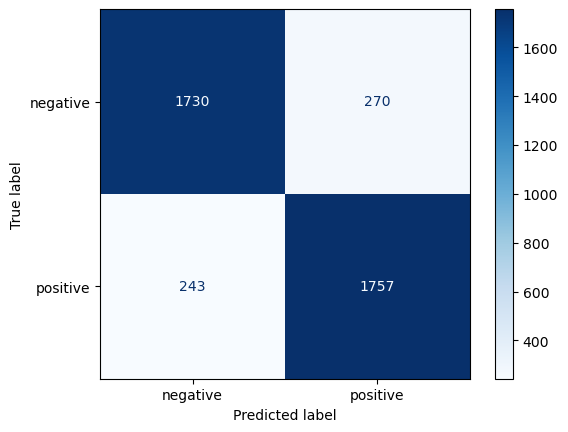

In [9]:
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, display_labels=['negative', 'positive'], cmap='Blues'
)

## 9. Most informative terms per sentiment

In [10]:
terms = tfidf.get_feature_names_out()
weights = model.coef_[0]
positive_idx = weights.argsort()[-15:][::-1]
negative_idx = weights.argsort()[:15]
top_positive = [(terms[i], float(weights[i])) for i in positive_idx]
top_negative = [(terms[i], float(weights[i])) for i in negative_idx]

print('TOP POSITIVE TERMS')
for term, weight in top_positive:
    print(f'{term:25s} {weight:+.4f}')
print('\nTOP NEGATIVE TERMS')
for term, weight in top_negative:
    print(f'{term:25s} {weight:+.4f}')

TOP POSITIVE TERMS
great                     +8.8051
excellent                 +6.2189
love                      +5.8224
best                      +5.6800
perfect                   +4.7078
easy                      +4.5340
awesome                   +4.2353
favorite                  +4.1454
wonderful                 +4.0371
amazing                   +3.9036
good                      +3.4845
life                      +3.3071
enjoyed                   +3.2894
fantastic                 +3.0559
must                      +2.8796

TOP NEGATIVE TERMS
boring                    -6.4274
disappointed              -5.8805
worst                     -5.6667
disappointing             -5.2802
waste                     -5.1684
terrible                  -5.0327
poor                      -4.9594
money                     -4.6670
horrible                  -4.5816
disappointment            -4.2712
bad                       -4.1991
awful                     -3.6121
poorly                    -3.5392
nothing  

## 10. Reusable sentiment function

In [11]:
def predict_sentiment(review):
    cleaned_review = clean_review(review)
    vector = tfidf.transform([cleaned_review])
    prediction = int(model.predict(vector)[0])
    confidence = float(model.predict_proba(vector)[0, prediction])
    return {
        'sentiment': 'positive' if prediction == 1 else 'negative',
        'confidence': round(confidence, 4)
    }

print(predict_sentiment('Excellent product. Works perfectly and I love it.'))
print(predict_sentiment('Terrible quality. Completely disappointed with this product.'))

{'sentiment': 'positive', 'confidence': 0.9795}
{'sentiment': 'negative', 'confidence': 0.9955}


## 11. Save the review-processing module

In [12]:
MODEL_PATH = MODELS_DIR / 'day12_sentiment_logreg.pkl'
TFIDF_PATH = MODELS_DIR / 'day12_tfidf.pkl'
METRICS_PATH = MODELS_DIR / 'day12_nlp_metrics.json'
TERMS_PATH = OUTPUT_DIR / 'informative_terms.json'

with open(MODEL_PATH, 'wb') as f:
    pickle.dump(model, f)
with open(TFIDF_PATH, 'wb') as f:
    pickle.dump(tfidf, f)
with open(METRICS_PATH, 'w') as f:
    json.dump({
        'reviews': len(texts),
        'accuracy': float(accuracy),
        'precision': float(precision),
        'recall': float(recall),
        'f1': float(f1)
    }, f, indent=2)
with open(TERMS_PATH, 'w') as f:
    json.dump({'positive': top_positive, 'negative': top_negative}, f, indent=2)

print('Saved:', MODEL_PATH.name)
print('Saved:', TFIDF_PATH.name)
print('Saved:', METRICS_PATH.name)
print('Saved:', TERMS_PATH.relative_to(PROJECT_ROOT))

Saved: day12_sentiment_logreg.pkl
Saved: day12_tfidf.pkl
Saved: day12_nlp_metrics.json
Saved: models/day12_nlp_outputs/informative_terms.json


## 12. Final summary

In [13]:
print('DAY 12 - NLP & CLASSICAL SENTIMENT BASELINE')
print('-' * 60)
print('Amazon reviews:', len(texts))
print('Model: Logistic Regression + TF-IDF')
print('Accuracy:', f'{accuracy:.4f}')
print('Precision:', f'{precision:.4f}')
print('Recall:', f'{recall:.4f}')
print('F1:', f'{f1:.4f}')
print('Top positive:', ', '.join(term for term, _ in top_positive[:8]))
print('Top negative:', ', '.join(term for term, _ in top_negative[:8]))

DAY 12 - NLP & CLASSICAL SENTIMENT BASELINE
------------------------------------------------------------
Amazon reviews: 20000
Model: Logistic Regression + TF-IDF
Accuracy: 0.8718
Precision: 0.8668
Recall: 0.8785
F1: 0.8726
Top positive: great, excellent, love, best, perfect, easy, awesome, favorite
Top negative: boring, disappointed, worst, disappointing, waste, terrible, poor, money


## Requirement coverage

- Amazon product reviews loaded
- Lowercase, noise removal, tokenization and stopword removal
- TF-IDF vectorization
- Logistic Regression sentiment baseline
- Accuracy/precision/recall/F1 evaluation plus confusion-matrix visual
- Most informative positive and negative terms surfaced
- Review-processing model/vectorizer persisted for later BERT upgrade

### Business value
Sentiment turns free-text reviews into customer-mood signals while informative terms expose recurring product strengths and issues.

### Open blocker
TF-IDF + Logistic Regression has limited context understanding. The next BERT iteration can model richer language meaning.